# Drift-weighted features

This notebook mirrors `src/drift_features.py`. The diagnostics showed that the models beat the naive baseline mainly on **suppliers whose behaviour is changing**. A fixed 30-day window treats a truck from 29 days ago the same as one from yesterday, so it reacts slowly. This step adds features that weight recent shipments more heavily, then tests whether they help.

The new columns are **added** to `features.parquet`; the original columns are never changed. A backup of the original feature set is saved once, as `features_v1.parquet`. The models choose which predictors to use through `models.FEATURE_SET` (`"v1"` original, `"v2"` with these features).

> All data is simulated. The simulator's `true_` values appear in one chart below, only to illustrate how quickly each feature reacts. They are never used to build or choose features.

## Setup

In [53]:
from pathlib import Path
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import shutil

import build_folds
from build_features import _asof, _cumulative_history, shipment_outcomes
from build_folds import PROCESSED, SCENARIOS
from models import DRIFT_COLUMNS

SCENARIO = "no_clusters"

In [54]:
HALF_LIFE_DAYS = 14.0


K_RATE = 5.0


K_DELAY = 2.0


TAU = HALF_LIFE_DAYS / np.log(2)

# Chart style: thin marks, recessive grid, categorical colours in a fixed order
COLORS = {"naive": "#2a78d6", "fast_1": "#eb6834", "third": "#1baf7a"}
MUTED, GRID, INK = "#898781", "#e1e0d9", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.facecolor": "#fcfcfb", "figure.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## Step 1 · Exponentially weighted history

Each past shipment gets a weight that halves every 14 days:

```
w = 0.5 ^ (age_in_days / 14)
```

Three weighted summaries are computed for each supplier, as of 72 hours before each delivery (the same leakage rule as every other feature):

| Column | Meaning |
|---|---|
| `sup_ewm_n` | effective number of recent shipments (sum of weights) |
| `sup_late_rate_ewm` | weighted late rate |
| `sup_late_delay_ewm` | weighted mean delay of late shipments |

**Shrinkage:** with only a few recent trucks, a weighted rate can swing wildly. So each one is pulled toward the supplier's long-run value, as if there were 5 extra shipments (2 for the delay) at the long-run rate:

```
late_rate_ewm = (Σ w·late + 5 · rate_all) / (Σ w + 5)
```

With few recent shipments the feature stays near the long-run level. With many, it follows the recent data.

**Computing it fast:** a weight `0.5^((c − t)/h)` splits into `exp(t/τ) · exp(−c/τ)`. So running totals of `value · exp(t/τ)`, looked up at each cutoff `c` with the same as-of method as `build_features.py`, give every weighted sum in a single pass.

In [55]:
def ewm_sums(ships: pd.DataFrame, origin: pd.Timestamp) -> pd.DataFrame:
    """Weighted sums sum(w), sum(w * late), sum(w * late * delay) per shipment,
    over that supplier's shipments known by the shipment's cutoff."""
    t_known = (ships["known_time"] - origin).dt.total_seconds() / 86400
    growth = np.exp(t_known / TAU)                     # exp(t / tau), finite for a year of data
    events = ships.assign(
        w=growth,
        w_late=growth * ships["late"].fillna(0.0),
        w_late_delay=growth * np.where(ships["late"] == 1, ships["delay_hours"], 0.0),
    )
    hist = _cumulative_history(events, ["supplier_code"], ["w", "w_late", "w_late_delay"])
    at_cutoff = _asof(ships, hist, ["supplier_code"], "cutoff")
    t_cut = (ships["cutoff"] - origin).dt.total_seconds() / 86400
    decay = np.exp(-t_cut / TAU).to_numpy()[:, None]   # exp(-c / tau)
    sums = at_cutoff[["cum_w", "cum_w_late", "cum_w_late_delay"]].to_numpy() * decay
    return pd.DataFrame(sums, columns=["sum_w", "sum_w_late", "sum_w_late_delay"], index=ships.index)


def drift_features(features: pd.DataFrame) -> pd.DataFrame:
    """The three new columns, one row per delivery row of `features`."""
    ships = shipment_outcomes(features)
    origin = features["production_date"].min().normalize()
    s = ewm_sums(ships, origin)

    first = features.drop_duplicates("shipment_id").set_index("shipment_id")
    rate_all = first.loc[ships["shipment_id"], "sup_late_rate_all"].to_numpy()
    delay_all = first.loc[ships["shipment_id"], "sup_mean_late_delay_all"].to_numpy()

    out = pd.DataFrame({
        "shipment_id": ships["shipment_id"].to_numpy(),
        "sup_ewm_n": s["sum_w"].to_numpy(),
        "sup_late_rate_ewm": (s["sum_w_late"] + K_RATE * rate_all) / (s["sum_w"] + K_RATE),
        "sup_late_delay_ewm": (s["sum_w_late_delay"] + K_DELAY * delay_all) / (s["sum_w_late"] + K_DELAY),
    })
    # With no long-run history the shrinkage target is missing -> leave NaN for the fold imputer
    out.loc[np.isnan(rate_all), "sup_late_rate_ewm"] = np.nan
    out.loc[np.isnan(delay_all), "sup_late_delay_ewm"] = np.nan
    return features[["shipment_id"]].merge(out, on="shipment_id", how="left")[list(DRIFT_COLUMNS)] \
        .set_index(features.index)

In [56]:
base = pd.read_parquet(PROCESSED / SCENARIO / (
    "features_v1.parquet" if (PROCESSED / SCENARIO / "features_v1.parquet").exists() else "features.parquet"))
base = base.drop(columns=[c for c in DRIFT_COLUMNS if c in base])
new = drift_features(base)
new.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
sup_late_rate_ewm,637773.0,0.102,0.084,0.00,0.041,0.078,0.137,1.000
sup_late_delay_ewm,628310.0,4.739,3.825,0.34,2.251,3.738,5.702,54.202
sup_ewm_n,645927.0,78.001,43.749,0.00,43.107,69.381,112.506,188.028


### How quickly does each feature react?

One supplier from the drift scenario that switched cluster at month 7. The chart compares its 30-day late rate, the new weighted late rate and the simulator's true late probability (used here only to show the reaction speed).

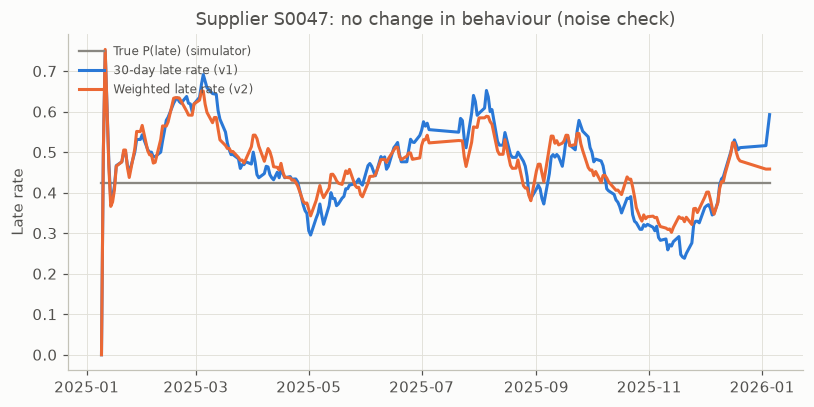

In [57]:
frame = pd.concat([base, new], axis=1).drop_duplicates("shipment_id")
suppliers = frame.drop_duplicates("supplier_code").set_index("supplier_code")
start = frame["production_date"].min()          # first day of the simulation, for every supplier
switchers = suppliers[suppliers["true_drift_month"].notna()]

if len(switchers):
    # Drift scenario: the supplier whose true P(late) changed the most
    example = (switchers["true_p_late_after"] - switchers["true_p_late"]).abs().idxmax()
    switch = start + pd.DateOffset(months=int(switchers.loc[example, "true_drift_month"]))
    title = f"Supplier {example}: reaction to a change in behaviour"
else:
    # No drift: a frequently-late supplier whose behaviour never changes,
    # to show how much each feature wanders from noise alone
    example = suppliers["true_p_late"].idxmax()
    switch = None
    title = f"Supplier {example}: no change in behaviour (noise check)"

d = frame[frame["supplier_code"] == example].sort_values("planned_delivery_datetime")
daily = (d.set_index("planned_delivery_datetime")[["sup_late_rate_30d", "sup_late_rate_ewm"]]
          .resample("D").mean().dropna())
before, after = suppliers.loc[example, "true_p_late"], suppliers.loc[example, "true_p_late_after"]
true_p = np.where(daily.index >= switch, after, before) if switch is not None else np.full(len(daily), before)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(daily.index, true_p, color=MUTED, linewidth=1.5, drawstyle="steps-post", label="True P(late) (simulator)")
ax.plot(daily.index, daily["sup_late_rate_30d"], color=COLORS["naive"], linewidth=2, label="30-day late rate (v1)")
ax.plot(daily.index, daily["sup_late_rate_ewm"], color=COLORS["fast_1"], linewidth=2, label="Weighted late rate (v2)")
if switch is not None:
    ax.axvline(switch, color=MUTED, linewidth=1, linestyle=":")
    ax.annotate("cluster switch", (switch, ax.get_ylim()[1] * 0.95), xytext=(4, 0),
                textcoords="offset points", color=MUTED, fontsize=8)
ax.set(ylabel="Late rate", title=title)
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

Both features lag the switch, because only trucks that arrived at least 72 hours before each delivery can count. More surprisingly, **the weighted rate does not react faster than the 30-day rate.** The two climb together, and afterwards the weighted rate sits slightly below. The cause is the shrinkage: it pulls the weighted rate toward the supplier's all-history rate, which right after a switch is still dominated by months of pre-switch behaviour. The safeguard against noise also anchors the feature to stale history. That's the first sign the gain will be small.

## Step 2 · Leakage check

The fast cumulative-sum method is recomputed by brute force for a sample of shipments, using only trucks that had arrived by each cutoff.

In [58]:
def check_no_leakage(features: pd.DataFrame, n_samples: int = 200, seed: int = 0) -> None:
    """Recompute the EWM features by brute force, using only shipments known by
    the cutoff, and confirm they match."""
    ships = shipment_outcomes(features)
    sample = features.drop_duplicates("shipment_id").sample(n_samples, random_state=seed)
    for _, row in sample.iterrows():
        h = ships[(ships["supplier_code"] == row["supplier_code"]) & (ships["known_time"] <= row["cutoff"])]
        age = (row["cutoff"] - h["known_time"]).dt.total_seconds() / 86400
        w = 0.5 ** (age / HALF_LIFE_DAYS)
        late = h["late"].fillna(0.0)
        assert np.isclose(w.sum(), row["sup_ewm_n"], rtol=1e-6, atol=1e-9), "sup_ewm_n mismatch"
        if pd.notna(row["sup_late_rate_all"]):
            expected = ((w * late).sum() + K_RATE * row["sup_late_rate_all"]) / (w.sum() + K_RATE)
            assert np.isclose(expected, row["sup_late_rate_ewm"], rtol=1e-6), "sup_late_rate_ewm mismatch"
    print(f"  leakage check passed on {n_samples} sampled shipments")

In [59]:
check_no_leakage(pd.concat([base, new], axis=1))

  leakage check passed on 200 sampled shipments


## Step 3 · Save next to the original features

`load_base` backs up the original feature set once (`features_v1.parquet`, `feature_columns_v1.json`), so reruns never stack new columns on top of old ones. `save` writes the combined file and adds the new columns to `delay_features` in `feature_columns.json`. The folds are then rebuilt, so each fold's imputation also covers the new columns.

The regression tests in `tests/test_feature_pipeline.py` confirm that the original columns, fold dates, cluster labels and imputation values all stay exactly the same.

In [60]:
def save(scenario: str, features: pd.DataFrame, new: pd.DataFrame) -> None:
    folder = PROCESSED / scenario
    truth = [c for c in features.columns if c.startswith("true_")]
    out = pd.concat([features.drop(columns=truth), new, features[truth]], axis=1)
    out.to_parquet(folder / "features.parquet", index=False)

    roles = json.loads((folder / "feature_columns_v1.json").read_text())
    roles["delay_features"] = roles["delay_features"] + list(DRIFT_COLUMNS)
    (folder / "feature_columns.json").write_text(json.dumps(roles, indent=2))


def load_base(scenario: str) -> pd.DataFrame:
    """The original feature set. Backed up on the first run so reruns never stack."""
    folder = PROCESSED / scenario
    if not (folder / "features_v1.parquet").exists():
        shutil.copy(folder / "features.parquet", folder / "features_v1.parquet")
        shutil.copy(folder / "feature_columns.json", folder / "feature_columns_v1.json")
    base = pd.read_parquet(folder / "features_v1.parquet")
    return base.drop(columns=[c for c in DRIFT_COLUMNS if c in base])

## Step 4 · Do they help?

Fast model 1 (from `diagnostics.py`) is fit with the original predictors (`v1`) and with the new ones added (`v2`) on every CV fold. `run` does all four steps for one scenario. It takes about a minute, mostly rebuilding the folds.

In [61]:
def compare_feature_sets(scenario: str) -> pd.DataFrame:
    from diagnostics import run as run_diagnostics
    v1 = run_diagnostics(scenario, "v1", verbose=False)["fold_comparison"]
    v2 = run_diagnostics(scenario, "v2", verbose=False)["fold_comparison"]
    table = pd.DataFrame({"fold_id": v1["fold_id"], "naive": v1["naive"],
                          "fast_1_v1": v1["fast_1"], "fast_1_v2": v2["fast_1"]})
    table["v2_minus_v1"] = table["fast_1_v2"] - table["fast_1_v1"]
    table["v2_vs_v1_pct"] = 100 * table["v2_minus_v1"] / table["fast_1_v1"]
    out = build_folds.ROOT / "results" / scenario / "diagnostics"
    out.mkdir(parents=True, exist_ok=True)
    table.to_csv(out / "feature_set_comparison.csv", index=False)
    return table


def run(scenario: str, compare: bool = True) -> None:
    print(f"[drift_features] scenario={scenario}")
    features = load_base(scenario)
    new = drift_features(features)
    save(scenario, features, new)
    check_no_leakage(pd.concat([features, new], axis=1))
    print(f"  wrote {PROCESSED / scenario / 'features.parquet'} (+{len(DRIFT_COLUMNS)} columns)")

    print("  rebuilding folds so imputation covers the new columns")
    build_folds.run(scenario)
    if compare:
        table = compare_feature_sets(scenario)
        print(table.round(4).to_string(index=False))
        print(f"  mean change v2 vs v1: {table['v2_minus_v1'].mean():+.4f} CRPS "
              f"({table['v2_vs_v1_pct'].mean():+.2f}%), better in {(table['v2_minus_v1'] < 0).sum()}/{len(table)} folds")

In [62]:
run(SCENARIO)

[drift_features] scenario=no_clusters
  leakage check passed on 200 sampled shipments
  wrote C:\Users\leer1\Documents\GitHub\bayesian-supplier-risk-engine-jit\data\processed\no_clusters\features.parquet (+3 columns)
  rebuilding folds so imputation covers the new columns
[folds] scenario=no_clusters
  fold_1: train 269,505 rows, test 33,114 rows, 355 suppliers clustered, k={'kmeans': 2, 'gmm': 2, 'hierarchical': 2}
  fold_2: train 306,934 rows, test 62,420 rows, 358 suppliers clustered, k={'kmeans': 2, 'gmm': 2, 'hierarchical': 2}
  fold_3: train 363,882 rows, test 55,272 rows, 366 suppliers clustered, k={'kmeans': 2, 'gmm': 2, 'hierarchical': 2}
  fold_4: train 424,594 rows, test 63,432 rows, 366 suppliers clustered, k={'kmeans': 2, 'gmm': 2, 'hierarchical': 2}
  holdout: train 485,306 rows, test 93,415 rows, 366 suppliers clustered, k={'kmeans': 2, 'gmm': 2, 'hierarchical': 2}
  selected algorithm for models 2 and 4: kmeans
  wrote C:\Users\leer1\Documents\GitHub\bayesian-supplier-r

All three scenarios, from each scenario's saved comparison:

In [63]:
rows = []
for s in SCENARIOS:
    path = ROOT / "results" / s / "diagnostics" / "feature_set_comparison.csv"
    if path.exists():
        t = pd.read_csv(path)
        rows.append({"scenario": s, "mean_change_crps": t["v2_minus_v1"].mean(),
                     "mean_change_pct": t["v2_vs_v1_pct"].mean(),
                     "folds_better": int((t["v2_minus_v1"] < 0).sum()), "folds": len(t)})
pd.DataFrame(rows).round(4)

,scenario,mean_change_crps,mean_change_pct,folds_better,folds
0,clusters,0.0000,0.0026,1,4
1,no_clusters,0.0000,0.0050,3,4
2,drift,-0.0001,-0.0035,2,4


## Verdict

The drift-weighted features **did not meet the bar for adoption:** a change bigger than the fold-to-fold noise (about 0.002 CRPS in the stable scenarios, about 0.008 under drift).

- **drift:** −0.0001 CRPS on average, better in 2 of 4 folds. The one clear gain (−0.28%) came in fold 2, the month when 10% of suppliers switch. Elsewhere the faster weighting added a little noise.
- **clusters, no_clusters:** no change.

**Why:** two things work against it.

- **Every feature lags a switch,** because the forecast is made 72 hours ahead and only arrived trucks count. The existing 30-day window already catches a switch within a few weeks.
- **The shrinkage anchors the weighted rate to the supplier's all-history rate,** which stays stale for months after a switch (see the supplier chart above).

Shrinking toward the 90-day rate instead might help. It would count as another variant against the budget, though, and the potential gain is bounded by how little the 30-day window lags already.

So `models.FEATURE_SET` stays `"v1"`. The new columns remain in `features.parquet`, and one switch (`--feature-set v2` on `evaluate_models.py`, or `FEATURE_SET = "v2"`) puts them in every model. This variant goes in the project's list of variants tried, which is reported alongside the holdout result.